In [1]:
import argparse
import csv
import os
import sys
from types import SimpleNamespace

from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "Sasyaaa230604"
AUTH = (USERNAME, PASSWORD)


In [2]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )


In [3]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")


Guinevere
Lancelot
Merlin


In [2]:
# !curl -L -o ecommerce-dataset.zip https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset


In [3]:
# !unzip ecommerce-dataset.zip


In [4]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(URI, auth=AUTH)
session = driver.session(database="system")


In [5]:
def parse_arguments():
    parser = argparse.ArgumentParser(description="Impor dataset RetailRocket (events.csv) ke database Neo4J.")
    parser.add_argument("-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default="neo4j", help="Password Neo4j (default: neo4j)")
    parser.add_argument("-b", "--bolt", default="neo4j://127.0.0.1:7687", help="Neo4j URI / Bolt (default: neo4j://127.0.0.1:7687)")
    parser.add_argument("-s", "--source", default="data", help="Direktori/folder sumber data (default: data)")
    return parser.parse_args()


In [6]:
args = SimpleNamespace(
    source=".",
    bolt="bolt://localhost:7687",
    user=USERNAME,
    password=PASSWORD,
)
csv_file_path = os.path.join(args.source, "events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File {csv_file_path} tidak ditemukan!")
    sys.exit(1)


In [7]:
try:
    driver = GraphDatabase.driver(args.bolt, auth=(args.user, args.password))
    driver.verify_connectivity()
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)


In [8]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: toInteger(row.visitorid)})
    MERGE (i:Item {itemId: toInteger(row.itemid)})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = "view"
        MERGE (v)-[:VIEWED {timestamp: toInteger(row.timestamp)}]->(i)
        UNION
        WITH v, i, row
        WITH v, i, row WHERE row.event = "addtocart"
        MERGE (v)-[:ADDED_TO_CART {timestamp: toInteger(row.timestamp)}]->(i)
        UNION
        WITH v, i, row
        WITH v, i, row WHERE row.event = "transaction"
        MERGE (v)-[:BOUGHT {timestamp: toInteger(row.timestamp), transactionId: row.transactionid}]->(i)
    }
    RETURN count(*)
    """
    tx.run(query, batch=batch)

batch_size = 1000

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(f"File tidak ditemukan: {csv_file_path}")

with driver.session(database="neo4j") as session:
    sudah_ada = session.run("MATCH (v:Visitor) RETURN count(v) AS n").single()["n"]

try:
    if sudah_ada > 0:
        print(f"Database sudah berisi {sudah_ada:,} Visitor, impor dilewati.")
    else:
        with driver.session(database="neo4j") as session:
            create_constraints(session)
            total_rows = 0
            buffer = []
            with open(csv_file_path, newline="", encoding="utf-8") as csv_file:
                reader = csv.DictReader(csv_file)
                for row in reader:
                    total_rows += 1
                    row["transactionid"] = str(row.get("transactionid") or "")
                    row["visitorid"] = int(float(row["visitorid"]))
                    row["itemid"] = int(float(row["itemid"]))
                    row["timestamp"] = int(float(row["timestamp"]))
                    buffer.append(row)
                    if len(buffer) >= batch_size:
                        session.execute_write(import_batch, buffer)
                        buffer = []
            if buffer:
                session.execute_write(import_batch, buffer)
            print(f"Total baris data: {total_rows}")
            print("Proses impor berhasil!")
except Exception as exc:
    print(f"Gagal mengimpor data: {exc}")
    raise


Database sudah berisi 1,407,580 Visitor, impor dilewati.


# 2.1 Wrangling dan EDA

## 1. Penentuan 2 periode waktu

Dataset RetailRocket (`events.csv`) hanya mencakup **03-05-2015 s.d. 18-09-2015**, sehingga periode
harus dipilih di dalam rentang tersebut:

| Fold | Periode | Kegunaan |
|---|---|---|
| **P1 (training)** | 12/05/2015 – 31/07/2015 | membangun VSM, proyeksi, similarity, dan model KNN |
| **P2 (testing)** | 01/08/2015 – 21/08/2015 | *ground truth* untuk evaluasi Hit@5 dan NDCG@5 |

Kedua fold berurutan tanpa tumpang tindih: P1 berakhir 31/07/2015 23:59:59 dan P2 dimulai 01/08/2015 00:00:00,
sehingga model dilatih pada masa lalu lalu diuji pada 3 minggu berikutnya.

Setiap interaksi diberi bobot sesuai kekuatan sinyalnya: `view` = 1, `addtocart` = 3, `transaction` = 5.

In [9]:
import time
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.preprocessing import normalize

P1_START = pd.Timestamp("2015-05-12 00:00:00", tz="UTC")
P1_END = pd.Timestamp("2015-07-31 23:59:59.999", tz="UTC")
P2_START = pd.Timestamp("2015-08-01 00:00:00", tz="UTC")
P2_END = pd.Timestamp("2015-08-21 23:59:59.999", tz="UTC")

# Batas periode dalam epoch milidetik (format kolom timestamp di events.csv dan di Neo4j).
to_ms = lambda ts: int(ts.timestamp() * 1000)
P1_MS = (to_ms(P1_START), to_ms(P1_END))
P2_MS = (to_ms(P2_START), to_ms(P2_END))

EVENT_WEIGHT = {"view": 1, "addtocart": 3, "transaction": 5}

pd.DataFrame(
    {"mulai": [P1_START, P2_START], "selesai": [P1_END, P2_END], "mulai_ms": [P1_MS[0], P2_MS[0]], "selesai_ms": [P1_MS[1], P2_MS[1]]},
    index=["P1 (training)", "P2 (testing)"],
)

,mulai,selesai,mulai_ms,selesai_ms
P1 (training),2015-05-12 00:00:00+00:00,2015-07-31 23:59:59.999000+00:00,1431388800000,1438387199999
P2 (testing),2015-08-01 00:00:00+00:00,2015-08-21 23:59:59.999000+00:00,1438387200000,1440201599999


## 2. Filter timestamp dan simpan ke CSV

Filter diterapkan pada kolom `timestamp` (epoch ms). Setiap baris diberi label `fold` (P1/P2) dan bobot `weight`,
lalu disimpan ke **`events_filtered_P1_P2.csv`**. Baris duplikat persis (visitor, item, event, timestamp yang sama)
dibuang karena di Neo4j baris seperti itu juga tergabung menjadi satu relasi oleh `MERGE`.

In [10]:
events = pd.read_csv("events.csv")

in_p1 = events["timestamp"].between(*P1_MS)
in_p2 = events["timestamp"].between(*P2_MS)

filtered = events.loc[in_p1 | in_p2].copy()
filtered["fold"] = np.where(in_p1[in_p1 | in_p2], "P1", "P2")
filtered["weight"] = filtered["event"].map(EVENT_WEIGHT)
filtered["event_time"] = pd.to_datetime(filtered["timestamp"], unit="ms", utc=True)
filtered = (
    filtered.drop_duplicates(["visitorid", "itemid", "event", "timestamp"])
    .sort_values("timestamp")
    .reset_index(drop=True)
)

FILTERED_CSV = "events_filtered_P1_P2.csv"
filtered.to_csv(FILTERED_CSV, index=False)

print(f"Total baris events.csv : {len(events):,}")
print(f"Total baris setelah filter: {len(filtered):,} -> disimpan ke {FILTERED_CSV}\n")
print(filtered.groupby("fold").agg(
    interaksi=("event", "size"),
    visitor=("visitorid", "nunique"),
    item=("itemid", "nunique"),
    awal=("event_time", "min"),
    akhir=("event_time", "max"),
))
print()
print(pd.crosstab(filtered["fold"], filtered["event"]))
filtered.head()

Total baris events.csv : 2,756,101
Total baris setelah filter: 2,113,691 -> disimpan ke events_filtered_P1_P2.csv



      interaksi  visitor    item                             awal  \
fold                                                                
P1      1735130   884614  192603 2015-05-12 00:00:03.576000+00:00   
P2       378561   215792   93162 2015-08-01 00:00:14.822000+00:00   

                                akhir  
fold                                   
P1   2015-07-31 23:59:58.354000+00:00  
P2   2015-08-21 23:59:59.243000+00:00  



event  addtocart  transaction     view
fold                                  
P1         42437        14186  1678507
P2         10004         3138   365419


,timestamp,visitorid,event,itemid,transactionid,fold,weight,event_time
0,1431388803576,320740,view,275609,NaN,P1,1,2015-05-12 00:00:03.576000+00:00
1,1431388815765,206122,view,449719,NaN,P1,1,2015-05-12 00:00:15.765000+00:00
2,1431388821876,754168,view,358051,NaN,P1,1,2015-05-12 00:00:21.876000+00:00
3,1431388827594,1165917,view,150547,NaN,P1,1,2015-05-12 00:00:27.594000+00:00
4,1431388829997,350566,view,256473,NaN,P1,1,2015-05-12 00:00:29.997000+00:00


## 3. Komposisi subgraph di Neo4j

Graf di Neo4j (container Docker `neo4j`) berisi seluruh `events.csv` dengan skema:

```
(:Visitor {visitorId})-[:VIEWED | :ADDED_TO_CART | :BOUGHT {timestamp, transactionId}]->(:Item {itemId})
```

Subgraph dibentuk dengan menerapkan filter timestamp yang sama langsung di Neo4j: setiap relasi yang
timestamp-nya jatuh di P1/P2 diberi properti `fold` dan `weight`. Relasi di luar kedua periode tidak diberi
`fold`, sehingga subgraph = semua relasi dengan `r.fold IS NOT NULL` beserta simpul di ujung-ujungnya.

```cypher
MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
CALL (r) {
  SET r.fold = CASE
        WHEN r.timestamp >= $p1_start AND r.timestamp <= $p1_end THEN 'P1'
        WHEN r.timestamp >= $p2_start AND r.timestamp <= $p2_end THEN 'P2'
        ELSE null END,
      r.weight = CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END
} IN TRANSACTIONS OF 50000 ROWS
```

- `MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()` mengambil semua relasi interaksi.
- `CALL (r) { ... } IN TRANSACTIONS OF 50000 ROWS` memproses update per 50.000 relasi agar memori transaksi tidak meledak.
- `CASE` memetakan timestamp ke fold (nilai `null` berarti properti dihapus, yaitu relasi di luar periode) dan tipe relasi ke bobot.

In [11]:
TAG_QUERY = '''
MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
CALL (r) {
  SET r.fold = CASE
        WHEN r.timestamp >= $p1_start AND r.timestamp <= $p1_end THEN 'P1'
        WHEN r.timestamp >= $p2_start AND r.timestamp <= $p2_end THEN 'P2'
        ELSE null END,
      r.weight = CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END
} IN TRANSACTIONS OF 50000 ROWS
'''

t0 = time.time()
# CALL ... IN TRANSACTIONS wajib dijalankan sebagai auto-commit transaction (session.run).
with driver.session(database="neo4j") as session:
    session.run(TAG_QUERY, p1_start=P1_MS[0], p1_end=P1_MS[1], p2_start=P2_MS[0], p2_end=P2_MS[1]).consume()
print(f"Penandaan fold selesai dalam {time.time() - t0:.1f} detik")

Penandaan fold selesai dalam 31.2 detik


Query komposisi subgraph:

```cypher
// (a) jenis dan jumlah simpul pada subgraph
MATCH (n)-[r:VIEWED|ADDED_TO_CART|BOUGHT]-()
WHERE r.fold IS NOT NULL
WITH DISTINCT n
RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah

// (b) jumlah simpul dan relasi per fold
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.fold IS NOT NULL
RETURN r.fold AS fold, count(DISTINCT v) AS visitor, count(DISTINCT i) AS item, count(r) AS relasi

// (c) jumlah relasi per jenis interaksi per fold
MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
WHERE r.fold IS NOT NULL
RETURN r.fold AS fold, type(r) AS jenis_relasi, count(*) AS jumlah
```

- **(a)** mencocokkan setiap simpul yang punya minimal satu relasi interaksi bertanda fold (arah relasi diabaikan),
  `WITH DISTINCT n` memastikan simpul dihitung sekali walau punya banyak relasi, lalu dikelompokkan per label.
- **(b)** mengikuti arah `Visitor -> Item`, dan `count(DISTINCT ...)` menghitung simpul unik di tiap fold.
- **(c)** mengelompokkan relasi berdasarkan `type(r)` untuk melihat proporsi view/add-to-cart/transaksi.

In [12]:
COMPOSITION_QUERIES = {
    "Jenis simpul pada subgraph": '''
        MATCH (n)-[r:VIEWED|ADDED_TO_CART|BOUGHT]-()
        WHERE r.fold IS NOT NULL
        WITH DISTINCT n
        RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
        ORDER BY jumlah DESC''',
    "Simpul & relasi per fold": '''
        MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
        WHERE r.fold IS NOT NULL
        RETURN r.fold AS fold, count(DISTINCT v) AS visitor, count(DISTINCT i) AS item, count(r) AS relasi
        ORDER BY fold''',
    "Relasi per jenis per fold": '''
        MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
        WHERE r.fold IS NOT NULL
        RETURN r.fold AS fold, type(r) AS jenis_relasi, count(*) AS jumlah
        ORDER BY fold, jumlah DESC''',
}

composition = {}
with driver.session(database="neo4j") as session:
    for title, query in COMPOSITION_QUERIES.items():
        composition[title] = pd.DataFrame(session.run(query).data())
        print(f"== {title} ==")
        print(composition[title].to_string(index=False), "\n")

total_db = composition["Jenis simpul pada subgraph"]["jumlah"].sum()
print(f"Total simpul subgraph: {total_db:,}")
print("Cek konsistensi dengan CSV:",
      f"visitor unik = {filtered['visitorid'].nunique():,}, item unik = {filtered['itemid'].nunique():,}")

== Jenis simpul pada subgraph ==
jenis_simpul  jumlah
     Visitor 1083222
        Item  210050 



== Simpul & relasi per fold ==
fold  visitor   item  relasi
  P1   884614 192603 1735130
  P2   215792  93162  378561 



== Relasi per jenis per fold ==
fold  jenis_relasi  jumlah
  P1        VIEWED 1678507
  P1 ADDED_TO_CART   42437
  P1        BOUGHT   14186
  P2        VIEWED  365419
  P2 ADDED_TO_CART   10004
  P2        BOUGHT    3138 

Total simpul subgraph: 1,293,272
Cek konsistensi dengan CSV: visitor unik = 1,083,222, item unik = 210,050


## 4. Vector Space Model (VSM) untuk User (Visitor)

Setiap visitor direpresentasikan sebagai vektor berdimensi **jumlah item** pada P1:

$$\vec{u} = (w_{u,1}, w_{u,2}, \dots, w_{u,|I|}), \quad w_{u,i} = \sum \text{bobot event visitor } u \text{ pada item } i$$

Matriks dense tidak mungkin dibuat (ratusan GB), sehingga dipakai **sparse CSR matrix** (`scipy.sparse`).
Proyeksi User adalah graf **User–User** (one-mode projection dari graf bipartit): dua visitor terhubung jika
pernah berinteraksi dengan item yang sama, dengan bobot = jumlah item yang sama ($B B^\top$, $B$ = matriks biner).

In [13]:
train = filtered[filtered["fold"] == "P1"]
test = filtered[filtered["fold"] == "P2"]

ui = train.groupby(["visitorid", "itemid"], as_index=False)["weight"].sum()
user_index = pd.Index(np.sort(ui["visitorid"].unique()), name="visitorid")
item_index = pd.Index(np.sort(ui["itemid"].unique()), name="itemid")

# X: matriks User x Item (VSM User). Baris = vektor visitor.
X = sp.csr_matrix(
    (ui["weight"].astype(np.float32), (user_index.get_indexer(ui["visitorid"]), item_index.get_indexer(ui["itemid"]))),
    shape=(len(user_index), len(item_index)),
)
B = X.copy()
B.data[:] = 1  # versi biner untuk menghitung co-occurrence pada proyeksi


def vsm_profile(M, name):
    nnz_per_row = M.getnnz(axis=1)
    return pd.Series({
        "jumlah vektor": M.shape[0],
        "dimensi vektor": M.shape[1],
        "shape": M.shape,
        "elemen non-zero": M.nnz,
        "density": M.nnz / (M.shape[0] * M.shape[1]),
        "rata-rata non-zero / vektor": nnz_per_row.mean(),
        "median non-zero / vektor": np.median(nnz_per_row),
        "maks non-zero / vektor": nnz_per_row.max(),
        "vektor dgn 1 non-zero (%)": 100 * (nnz_per_row == 1).mean(),
        "memori sparse (MB)": (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6,
        "memori jika dense (GB)": M.shape[0] * M.shape[1] * 4 / 1e9,
    }, name=name)


def projection(Bin):
    t0 = time.time()
    P = (Bin @ Bin.T).tocsr()
    P.setdiag(0)
    P.eliminate_zeros()
    elapsed = time.time() - t0
    deg = P.getnnz(axis=1)
    n = P.shape[0]
    stats = pd.Series({
        "simpul proyeksi": n,
        "simpul terisolasi (%)": 100 * (deg == 0).mean(),
        "edge proyeksi": P.nnz // 2,
        "rata-rata degree": deg.mean(),
        "density proyeksi": P.nnz / (n * (n - 1)),
        "memori proyeksi (MB)": (P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 1e6,
        "waktu hitung (detik)": elapsed,
    })
    return P, stats


def plot_ego(P, labels, center, prefix, title, ax, max_neighbors=25):
    row = P.getrow(center)
    neighbors = row.indices[np.argsort(-row.data, kind="stable")[:max_neighbors]]
    nodes = np.r_[center, neighbors]
    G = nx.from_scipy_sparse_array(P[nodes][:, nodes])
    G = nx.relabel_nodes(G, {k: f"{prefix}{labels[n]}" for k, n in enumerate(nodes)})
    pos = nx.spring_layout(G, seed=42, weight=None)
    center_name = f"{prefix}{labels[center]}"
    widths = [0.4 + 0.6 * np.log1p(d["weight"]) for _, _, d in G.edges(data=True)]
    nx.draw_networkx_edges(G, pos, ax=ax, width=widths, edge_color="#bbbbbb")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[500 if n == center_name else 160 for n in G],
                           node_color=["#d62728" if n == center_name else "#1f77b4" for n in G])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
    ax.set_title(title)
    ax.axis("off")
    return G


user_profile = vsm_profile(X, "VSM User")
print(user_profile.to_string())

print("\nContoh 5 vektor User (hanya elemen non-zero yang ditampilkan):")
for r in range(5):
    row = X.getrow(r)
    print(f"  U{user_index[r]}: {dict(zip(item_index[row.indices].tolist(), row.data.astype(int).tolist()))}")

jumlah vektor                            884614
dimensi vektor                           192603
shape                          (884614, 192603)
elemen non-zero                         1347582
density                                0.000008
rata-rata non-zero / vektor            1.523356
median non-zero / vektor                    1.0
maks non-zero / vektor                     2528
vektor dgn 1 non-zero (%)             79.779655
memori sparse (MB)                    14.319116
memori jika dense (GB)               681.517241

Contoh 5 vektor User (hanya elemen non-zero yang ditampilkan):
  U5: {61396: 1}
  U7: {139394: 1, 164941: 1, 226353: 1}
  U8: {434230: 1}
  U9: {222422: 1}
  U13: {278689: 1, 320589: 1}


Proyeksi User-User:
simpul proyeksi          8.846140e+05
simpul terisolasi (%)    5.239573e+00
edge proyeksi            3.705943e+07
rata-rata degree         8.378668e+01
density proyeksi         9.471563e-05
memori proyeksi (MB)     5.964894e+02
waktu hitung (detik)     2.355549e+00


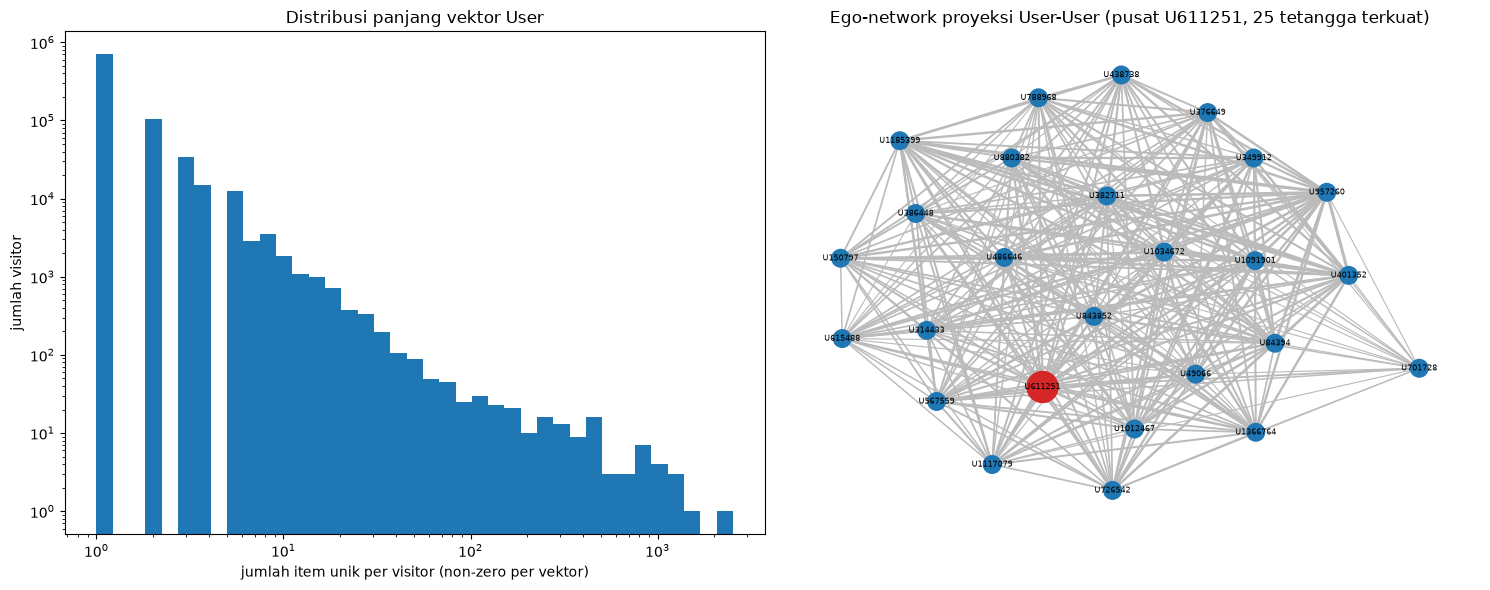

Plot: 26 simpul, 315 edge


In [14]:
P_user, user_proj_stats = projection(B)
print("Proyeksi User-User:")
print(user_proj_stats.to_string())

# Visitor pusat untuk plot: visitor paling aktif dengan riwayat <= 20 item (menghindari akun bot).
items_per_user = X.getnnz(axis=1)
candidates = np.where(items_per_user <= 20)[0]
center_user = candidates[np.argmax(P_user.getnnz(axis=1)[candidates])]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].hist(items_per_user, bins=np.logspace(0, np.log10(items_per_user.max() + 1), 40), color="#1f77b4")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("jumlah item unik per visitor (non-zero per vektor)"); axes[0].set_ylabel("jumlah visitor")
axes[0].set_title("Distribusi panjang vektor User")
G_user_plot = plot_ego(P_user, user_index, center_user, "U",
                       f"Ego-network proyeksi User-User (pusat U{user_index[center_user]}, 25 tetangga terkuat)", axes[1])
plt.tight_layout()
plt.show()
print(f"Plot: {G_user_plot.number_of_nodes()} simpul, {G_user_plot.number_of_edges()} edge")

**Karakteristik VSM User:** 885 ribu vektor berdimensi 193 ribu dengan density ~$10^{-5}$. Sebagian besar
visitor (~80%) hanya punya **1 elemen non-zero**, sehingga vektornya nyaris kosong. Distribusinya
*long-tail* (median 1 item, maksimum >2.500 item, kemungkinan bot/crawler). Proyeksi User–User menjadi graf yang
sangat besar (puluhan juta edge), namun banyak simpulnya hanya terhubung karena kebetulan melihat satu item
populer yang sama.

## 5. Vector Space Model (VSM) untuk Item

Setiap item direpresentasikan sebagai vektor berdimensi **jumlah visitor** pada P1, yaitu transpos dari VSM User:

$$\vec{i} = (w_{1,i}, w_{2,i}, \dots, w_{|U|,i})$$

Proyeksi Item adalah graf **Item–Item**: dua item terhubung jika pernah disentuh visitor yang sama ($B^\top B$).

In [15]:
X_item = X.T.tocsr()  # matriks Item x User
B_item = B.T.tocsr()

item_profile = vsm_profile(X_item, "VSM Item")
print(item_profile.to_string())

print("\nContoh 5 vektor Item (hanya elemen non-zero yang ditampilkan):")
for r in range(5):
    row = X_item.getrow(r)
    print(f"  I{item_index[r]}: {dict(list(zip(user_index[row.indices].tolist(), row.data.astype(int).tolist()))[:8])}"
          f"{' ...' if row.nnz > 8 else ''}")

jumlah vektor                            192603
dimensi vektor                           884614
shape                          (192603, 884614)
elemen non-zero                         1347582
density                                0.000008
rata-rata non-zero / vektor            6.996682
median non-zero / vektor                    2.0
maks non-zero / vektor                     1666
vektor dgn 1 non-zero (%)             38.241357
memori sparse (MB)                    11.551072
memori jika dense (GB)               681.517241

Contoh 5 vektor Item (hanya elemen non-zero yang ditampilkan):
  I4: {1042455: 1}
  I6: {13953: 1, 175267: 1, 183491: 1, 275013: 1, 316532: 1, 360541: 1, 496704: 1, 539918: 1} ...
  I9: {949658: 1, 1205411: 1}
  I15: {88808: 1, 232847: 1, 633965: 1, 724401: 2, 825021: 1, 863219: 1, 960459: 1, 989647: 2} ...
  I16: {101249: 1, 271241: 1, 286722: 1, 375506: 1, 534240: 1, 550789: 1, 572889: 1, 843371: 1} ...


Proyeksi Item-Item:
simpul proyeksi          1.926030e+05
simpul terisolasi (%)    3.688780e+01
edge proyeksi            1.646733e+07
rata-rata degree         1.709977e+02
density proyeksi         8.878291e-04
memori proyeksi (MB)     2.642477e+02
waktu hitung (detik)     7.402740e-01


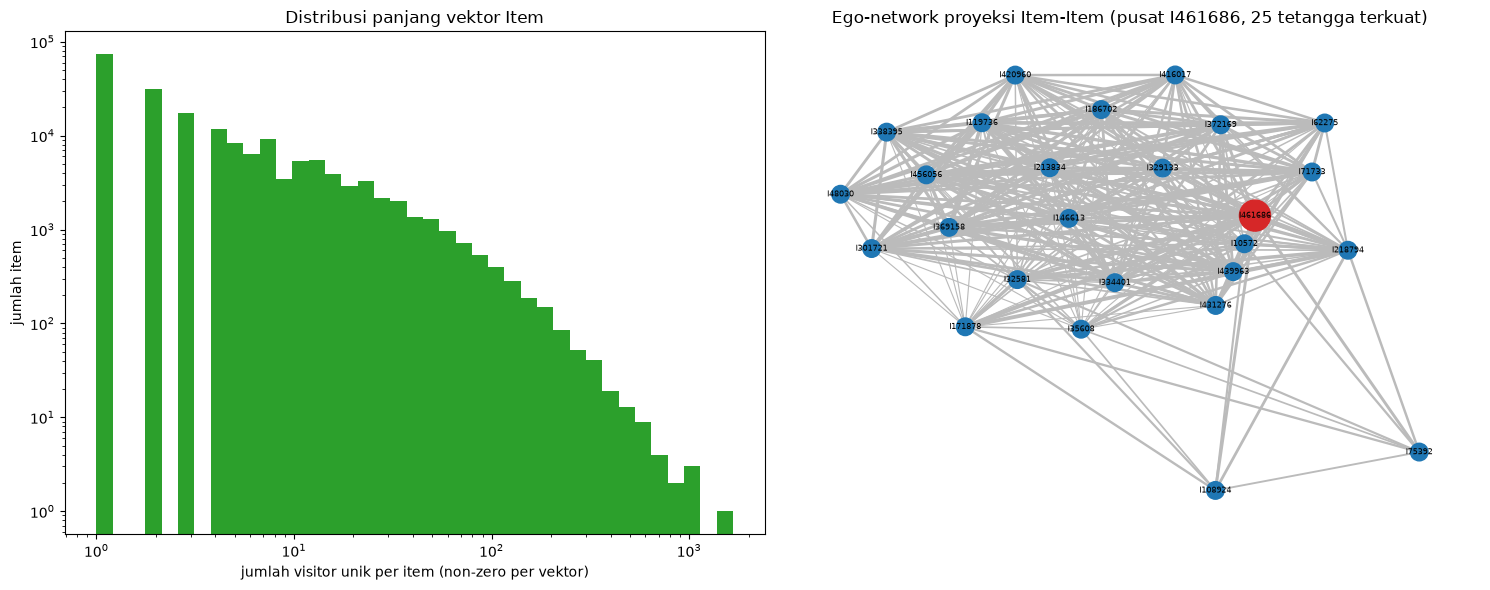

Plot: 26 simpul, 286 edge


In [16]:
P_item, item_proj_stats = projection(B_item)
print("Proyeksi Item-Item:")
print(item_proj_stats.to_string())

# Item acuan: item dengan total bobot interaksi terbesar di P1.
ref_pos = int(np.asarray(X_item.sum(axis=1)).ravel().argmax())
REF_ITEM = int(item_index[ref_pos])

users_per_item = X_item.getnnz(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].hist(users_per_item, bins=np.logspace(0, np.log10(users_per_item.max() + 1), 40), color="#2ca02c")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("jumlah visitor unik per item (non-zero per vektor)"); axes[0].set_ylabel("jumlah item")
axes[0].set_title("Distribusi panjang vektor Item")
G_item_plot = plot_ego(P_item, item_index, ref_pos, "I",
                       f"Ego-network proyeksi Item-Item (pusat I{REF_ITEM}, 25 tetangga terkuat)", axes[1])
plt.tight_layout()
plt.show()
print(f"Plot: {G_item_plot.number_of_nodes()} simpul, {G_item_plot.number_of_edges()} edge")

**Karakteristik VSM Item:** 193 ribu vektor berdimensi 885 ribu. Jumlah non-zero sama dengan VSM User
(matriksnya hanya ditranspos), tetapi tersebar pada **jumlah vektor yang jauh lebih sedikit**, sehingga
setiap vektor item rata-rata berisi ~7 visitor (vs ~1,5 item per visitor). Ego-network item terlihat
lebih rapat: tetangga-tetangganya juga saling terhubung (membentuk klaster produk sejenis).

## 6. Perbandingan proyeksi: mana yang lebih baik?

In [17]:
comparison = pd.concat([
    pd.concat([user_profile, user_proj_stats]).rename("Proyeksi User (User-User)"),
    pd.concat([item_profile, item_proj_stats]).rename("Proyeksi Item (Item-Item)"),
], axis=1)
comparison

,Proyeksi User (User-User),Proyeksi Item (Item-Item)
jumlah vektor,884614,192603
dimensi vektor,192603,884614
shape,"(884614, 192603)","(192603, 884614)"
elemen non-zero,1347582,1347582
density,0.000008,0.000008
rata-rata non-zero / vektor,1.523356,6.996682
median non-zero / vektor,1.0,2.0
maks non-zero / vektor,2528,1666
vektor dgn 1 non-zero (%),79.779655,38.241357
memori sparse (MB),14.319116,11.551072


**Kesimpulan: proyeksi Item (Item–Item) lebih baik**, baik dari sisi efisiensi maupun efektivitas.

*Efisiensi*
- Jumlah simpul proyeksi Item ~4,6× lebih sedikit (193 ribu vs 885 ribu), dan jumlah edge-nya kurang dari
  setengah proyeksi User (16,5 juta vs 37,1 juta). Memori (264 MB vs 596 MB) dan waktu komputasinya juga lebih kecil.
- Matriks similarity Item–Item bisa dihitung sekali (offline) lalu dipakai untuk semua visitor,
  sedangkan populasi visitor terus bertambah dan berganti (885 ribu visitor di P1, hanya ~17 ribu yang kembali di P2).

*Efektivitas*
- Vektor item lebih "padat" (rata-rata ~7,0 non-zero vs ~1,5 pada vektor user). Sekitar 80% vektor user
  hanya punya 1 non-zero, sehingga cosine similarity antar-user hampir selalu 0 atau 1 dan kurang informatif.
- Proyeksi User memang punya lebih sedikit simpul terisolasi (5% vs 37%), tetapi konektivitas itu semu: sebagian
  besar user terhubung hanya karena melihat 1 item populer yang sama (vektornya hanya 1 non-zero), sehingga
  tetangganya tidak membawa informasi preferensi. Simpul Item yang terisolasi adalah item *long-tail* yang hanya
  disentuh 1 visitor; ~122 ribu item lainnya punya tetangga dengan bobot co-occurrence yang lebih bermakna.
- Preferensi terhadap item lebih stabil dari waktu ke waktu dibanding perilaku visitor anonim, cocok untuk
  memprediksi periode P2.

Karena itu, similarity (no. 7) dan KNN (Analytics) dihitung pada **proyeksi Item**.

## 7. Perhitungan similarity pada graf terproyeksi (Python)

Similarity antar-item memakai **cosine similarity** pada vektor item berbobot:

$$\text{sim}(a,b) = \frac{\vec{a}\cdot\vec{b}}{\lVert\vec{a}\rVert\,\lVert\vec{b}\rVert}
= \frac{\sum_u w_{u,a}\,w_{u,b}}{\sqrt{\sum_u w_{u,a}^2}\,\sqrt{\sum_u w_{u,b}^2}}$$

Dengan vektor yang sudah dinormalisasi L2, seluruh matriks similarity cukup dihitung dengan satu perkalian sparse
$S = \hat{X}_{item}\hat{X}_{item}^\top$. Nilai non-zero $S$ tepat berada pada edge proyeksi Item–Item.

**Record acuan:** item dengan total bobot interaksi terbesar pada P1 (`REF_ITEM`).

In [18]:
t0 = time.time()
X_item_norm = normalize(X_item, norm="l2", axis=1)
S = (X_item_norm @ X_item_norm.T).tocsr()
S.setdiag(0)
S.eliminate_zeros()
print(f"Matriks similarity Item-Item: shape {S.shape}, {S.nnz // 2:,} pasangan non-zero, {time.time() - t0:.1f} detik")


def top_similar(pos, k=5):
    row = S.getrow(pos)
    # urutkan skor menurun, item id menaik sebagai tie-breaker (sama dengan ORDER BY di Cypher)
    order = np.lexsort((item_index[row.indices], -row.data))[:k]
    return pd.DataFrame({"itemId": item_index[row.indices[order]], "similarity": row.data[order].astype(float)})


print(f"\nItem acuan: {REF_ITEM} | visitor unik P1 = {users_per_item[ref_pos]}")
top5_python = top_similar(ref_pos)
top5_python.index = np.arange(1, len(top5_python) + 1)
top5_python

Matriks similarity Item-Item: shape (192603, 192603), 16,467,332 pasangan non-zero, 0.8 detik

Item acuan: 461686 | visitor unik P1 = 690


,itemId,similarity
1,218794,0.378314
2,171878,0.368817
3,32581,0.345948
4,50254,0.259665
5,63338,0.259665


### 7(a). CYPHER untuk mendapatkan 5 record dengan similarity tertinggi

Query di bawah menghitung cosine similarity yang sama langsung dari graf bipartit di Neo4j (hanya relasi `fold = 'P1'`):

```cypher
// 1. Norma vektor item acuan: sqrt(sum bobot^2) per visitor
MATCH (ref:Item {itemId: $ref})<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WHERE r.fold = 'P1'
WITH ref, v, sum(r.weight) AS wa
WITH ref, collect({v: v, wa: wa}) AS vecA, sqrt(sum(wa * wa)) AS normA
// 2. Dot product dengan setiap item lain yang disentuh visitor yang sama
UNWIND vecA AS a
WITH ref, normA, a.v AS v, a.wa AS wa
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE r2.fold = 'P1' AND other <> ref
WITH ref, normA, other, v, wa, sum(r2.weight) AS wb
WITH ref, normA, other, sum(wa * wb) AS dot
// 3. Norma vektor item kandidat
CALL (other) {
  MATCH (other)<-[r3:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
  WHERE r3.fold = 'P1'
  WITH u, sum(r3.weight) AS wb
  RETURN sqrt(sum(wb * wb)) AS normB
}
RETURN ref.itemId AS source, other.itemId AS target, dot / (normA * normB) AS similarity
ORDER BY similarity DESC, target ASC
LIMIT 5
```

Penjelasan:
1. `sum(r.weight)` per visitor membentuk elemen vektor item acuan $w_{u,ref}$, lalu `normA` = panjang vektornya.
2. Dari setiap visitor tersebut ditelusuri item lain (`other`) di P1. `sum(wa * wb)` = dot product (hanya visitor
   yang sama-sama berinteraksi yang berkontribusi, sisanya 0).
3. Subquery `CALL (other)` menghitung norma vektor kandidat, lalu dot dibagi hasil kali kedua norma.

In [19]:
COSINE_TOP5_CYPHER = '''
MATCH (ref:Item {itemId: $ref})<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WHERE r.fold = 'P1'
WITH ref, v, sum(r.weight) AS wa
WITH ref, collect({v: v, wa: wa}) AS vecA, sqrt(sum(wa * wa)) AS normA
UNWIND vecA AS a
WITH ref, normA, a.v AS v, a.wa AS wa
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE r2.fold = 'P1' AND other <> ref
WITH ref, normA, other, v, wa, sum(r2.weight) AS wb
WITH ref, normA, other, sum(wa * wb) AS dot
CALL (other) {
  MATCH (other)<-[r3:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
  WHERE r3.fold = 'P1'
  WITH u, sum(r3.weight) AS wb
  RETURN sqrt(sum(wb * wb)) AS normB
}
RETURN ref.itemId AS source, other.itemId AS target, dot / (normA * normB) AS similarity
ORDER BY similarity DESC, target ASC
LIMIT 5
'''

t0 = time.time()
with driver.session(database="neo4j") as session:
    top5_cypher = pd.DataFrame(session.run(COSINE_TOP5_CYPHER, ref=REF_ITEM).data())
top5_cypher.index = np.arange(1, len(top5_cypher) + 1)
print(f"Query Cypher selesai dalam {time.time() - t0:.1f} detik")
print("Hasil sama dengan perhitungan Python:",
      np.array_equal(top5_cypher["target"].to_numpy(), top5_python["itemId"].to_numpy())
      and np.allclose(top5_cypher["similarity"], top5_python["similarity"], atol=1e-5))
top5_cypher

Query Cypher selesai dalam 1.1 detik
Hasil sama dengan perhitungan Python: True


,source,target,similarity
1,461686,218794,0.378314
2,461686,171878,0.368817
3,461686,32581,0.345948
4,461686,50254,0.259665
5,461686,63338,0.259665


### 7(b). Menulis nilai similarity kembali ke graf

Nilai similarity hasil Python ditulis sebagai relasi baru `(:Item)-[:SIMILAR_TO {score, method, fold}]->(:Item)`.
Seluruh relasi `SIMILAR_TO` lama dihapus dulu agar sel ini aman dijalankan ulang (termasuk sisa dari item acuan lain).
Kondisi graf **sebelum** penulisan direkam terlebih dahulu untuk no. 8.

```cypher
// tulis similarity
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.target})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.similarity, s.method = 'cosine', s.fold = 'P1'

// tampilkan hasil
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS source, b.itemId AS target, s.score AS similarity, s.method AS method, s.fold AS fold
ORDER BY s.score DESC, target ASC
```

In [20]:
TARGETS = top5_python["itemId"].astype(int).tolist()

# Graf di sekitar item acuan: item acuan, 5 item paling mirip, beberapa visitor yang menjembatani, dan SIMILAR_TO (jika ada).
NEIGHBORHOOD_CYPHER = '''
MATCH (ref:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN $targets
WITH ref, o, v, r1, r2 ORDER BY v.visitorId
WITH ref, o, collect({v: v, r1: r1, r2: r2})[0..3] AS bridges
UNWIND bridges AS b
RETURN 'Visitor' AS src_label, b.v.visitorId AS src, type(b.r1) AS rel, 'Item' AS dst_label, ref.itemId AS dst, null AS score
UNION
MATCH (ref:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN $targets
WITH o, v, r2 ORDER BY v.visitorId
WITH o, collect({v: v, r2: r2})[0..3] AS bridges
UNWIND bridges AS b
RETURN 'Visitor' AS src_label, b.v.visitorId AS src, type(b.r2) AS rel, 'Item' AS dst_label, o.itemId AS dst, null AS score
UNION
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN 'Item' AS src_label, a.itemId AS src, 'SIMILAR_TO' AS rel, 'Item' AS dst_label, b.itemId AS dst, s.score AS score
'''
COUNT_SIMILAR_CYPHER = "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS total_similar_to"
WRITE_SIMILAR_CYPHER = '''
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.target})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.similarity, s.method = 'cosine', s.fold = 'P1'
'''
READ_SIMILAR_CYPHER = '''
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS source, b.itemId AS target, s.score AS similarity, s.method AS method, s.fold AS fold
ORDER BY s.score DESC, target ASC
'''

rows = [{"target": int(t), "similarity": float(s)} for t, s in zip(top5_python["itemId"], top5_python["similarity"])]
# Sebelum ditulis, tipe relasi SIMILAR_TO belum ada; peringatan "UNRECOGNIZED" dari server dimatikan.
with driver.session(database="neo4j", notifications_disabled_classifications=["UNRECOGNIZED"]) as session:
    session.run("MATCH ()-[s:SIMILAR_TO]->() DELETE s").consume()

    before_count = session.run(COUNT_SIMILAR_CYPHER).single()["total_similar_to"]
    before_edges = pd.DataFrame(session.run(NEIGHBORHOOD_CYPHER, ref=REF_ITEM, targets=TARGETS).data())

    session.run(WRITE_SIMILAR_CYPHER, ref=REF_ITEM, rows=rows).consume()

    after_count = session.run(COUNT_SIMILAR_CYPHER).single()["total_similar_to"]
    after_edges = pd.DataFrame(session.run(NEIGHBORHOOD_CYPHER, ref=REF_ITEM, targets=TARGETS).data())
    similar_written = pd.DataFrame(session.run(READ_SIMILAR_CYPHER, ref=REF_ITEM).data())

print(f"Jumlah relasi SIMILAR_TO sebelum: {before_count}, sesudah: {after_count}\n")
print("Hasil query SIMILAR_TO di Neo4j:")
similar_written

Jumlah relasi SIMILAR_TO sebelum: 0, sesudah: 5

Hasil query SIMILAR_TO di Neo4j:


,source,target,similarity,method,fold
0,461686,218794,0.378314,cosine,P1
1,461686,171878,0.368817,cosine,P1
2,461686,32581,0.345948,cosine,P1
3,461686,50254,0.259665,cosine,P1
4,461686,63338,0.259665,cosine,P1


## 8. Kondisi graf sebelum dan sesudah perhitungan similarity

CYPHER yang dipakai (sama untuk kondisi sebelum dan sesudah; bagian ketiga `UNION` hanya mengembalikan baris jika
relasi `SIMILAR_TO` sudah ada):

```cypher
// visitor penghubung -> item acuan (maks. 3 visitor per item target)
MATCH (ref:Item {itemId: $ref})<-[r1]-(v:Visitor)-[r2]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN $targets
...
RETURN 'Visitor' AS src_label, v.visitorId AS src, type(r1) AS rel, 'Item' AS dst_label, ref.itemId AS dst
UNION
// visitor penghubung -> item target
...
UNION
// lapisan similarity
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN 'Item' AS src_label, a.itemId AS src, 'SIMILAR_TO' AS rel, 'Item' AS dst_label, b.itemId AS dst, s.score AS score
```

Untuk dilihat langsung di **Neo4j Browser** (http://localhost:7474):

```cypher
// SEBELUM: hanya relasi interaksi Visitor -> Item
MATCH p = (ref:Item {itemId: <REF_ITEM>})<-[r1]-(v:Visitor)-[r2]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN [<5 item target>]
RETURN p LIMIT 30

// SESUDAH: ditambah lapisan SIMILAR_TO
MATCH p = (ref:Item {itemId: <REF_ITEM>})<-[r1]-(v:Visitor)-[r2]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN [<5 item target>]
RETURN p LIMIT 30
UNION
MATCH p = (:Item {itemId: <REF_ITEM>})-[:SIMILAR_TO]->(:Item)
RETURN p
```

Query Neo4j Browser dengan nilai aktual:

MATCH p = (ref:Item {itemId: 461686})<-[r1]-(v:Visitor)-[r2]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN [218794, 171878, 32581, 50254, 63338]
RETURN p LIMIT 30
UNION
MATCH p = (:Item {itemId: 461686})-[:SIMILAR_TO]->(:Item)
RETURN p

SEBELUM:
src_label     src           rel dst_label    dst score
  Visitor    2951        VIEWED      Item 461686  None
  Visitor   22084        VIEWED      Item 461686  None
  Visitor   15239        VIEWED      Item 461686  None
  Visitor   23087        VIEWED      Item 461686  None
  Visitor 1150086        VIEWED      Item 461686  None
  Visitor    2951        VIEWED      Item  32581  None
  Visitor   22084        VIEWED      Item  32581  None
  Visitor   22084 ADDED_TO_CART      Item  32581  None
  Visitor   15239        VIEWED      Item 171878  None
  Visitor   22084        VIEWED      Item 218794  None
  Visitor   23087        VIEWED      Item 218794  None
  Visitor 1150086        VIEWED 

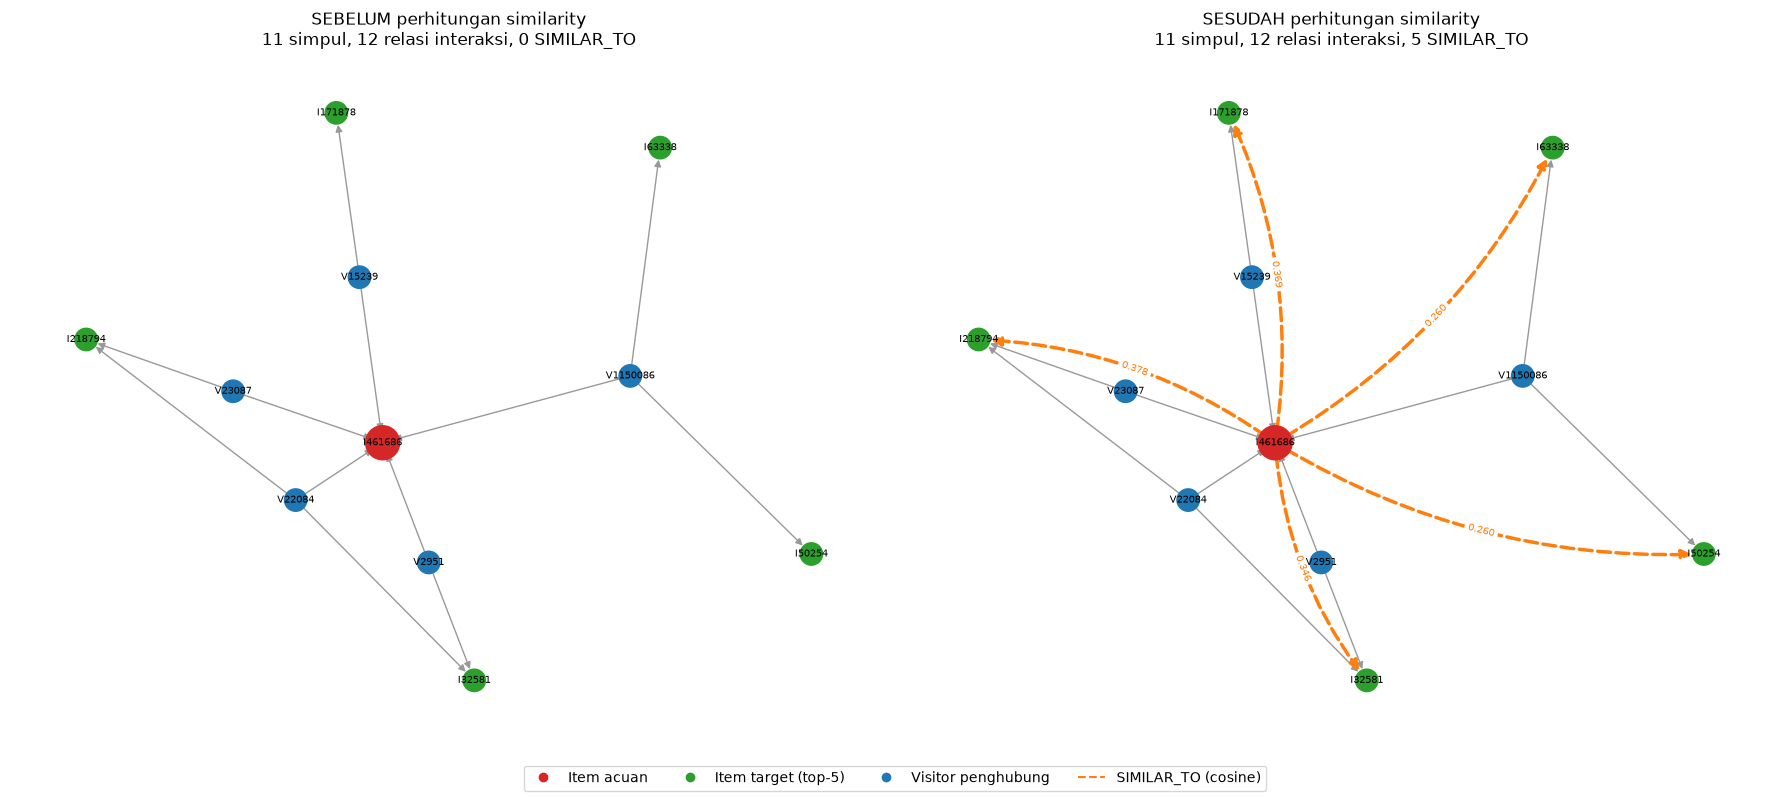

In [21]:
print("Query Neo4j Browser dengan nilai aktual:\n")
print(f'''MATCH p = (ref:Item {{itemId: {REF_ITEM}}})<-[r1]-(v:Visitor)-[r2]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN {TARGETS}
RETURN p LIMIT 30
UNION
MATCH p = (:Item {{itemId: {REF_ITEM}}})-[:SIMILAR_TO]->(:Item)
RETURN p
''')

print("SEBELUM:")
print(before_edges.to_string(index=False))
print("\nSESUDAH (baris tambahan):")
print(after_edges[after_edges["rel"] == "SIMILAR_TO"].to_string(index=False))


def draw_state(edges, ax, title):
    G = nx.DiGraph()
    for e in edges.itertuples(index=False):
        src = f"{e.src_label[0]}{e.src}"
        dst = f"{e.dst_label[0]}{e.dst}"
        G.add_node(src, label=e.src_label)
        G.add_node(dst, label=e.dst_label)
        G.add_edge(src, dst, rel=e.rel, score=e.score)
    ref_name = f"I{REF_ITEM}"
    # tata letak tetap (sama untuk kedua kondisi): item acuan di tengah, item target melingkar, visitor di antaranya
    pos = nx.spring_layout(G, seed=7, pos={ref_name: (0, 0)}, fixed=[ref_name])
    colors = ["#d62728" if n == ref_name else "#2ca02c" if G.nodes[n]["label"] == "Item" else "#1f77b4" for n in G]
    inter = [(u, v) for u, v, d in G.edges(data=True) if d["rel"] != "SIMILAR_TO"]
    sim = [(u, v) for u, v, d in G.edges(data=True) if d["rel"] == "SIMILAR_TO"]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=[600 if n == ref_name else 260 for n in G])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=inter, edge_color="#999999", arrows=True, arrowsize=10)
    if sim:
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=sim, edge_color="#ff7f0e", width=2.5, style="dashed",
                               arrows=True, arrowsize=14, connectionstyle="arc3,rad=0.15")
        nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=7, font_color="#ff7f0e",
                                     edge_labels={(u, v): f"{G[u][v]['score']:.3f}" for u, v in sim},
                                     connectionstyle="arc3,rad=0.15")
    ax.set_title(f"{title}\n{G.number_of_nodes()} simpul, {len(inter)} relasi interaksi, {len(sim)} SIMILAR_TO")
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(18, 8))
draw_state(before_edges, axes[0], "SEBELUM perhitungan similarity")
draw_state(after_edges, axes[1], "SESUDAH perhitungan similarity")
fig.legend(handles=[
    plt.Line2D([], [], marker="o", ls="", color="#d62728", label="Item acuan"),
    plt.Line2D([], [], marker="o", ls="", color="#2ca02c", label="Item target (top-5)"),
    plt.Line2D([], [], marker="o", ls="", color="#1f77b4", label="Visitor penghubung"),
    plt.Line2D([], [], color="#ff7f0e", ls="--", label="SIMILAR_TO (cosine)"),
], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

Sebelum similarity dihitung, hubungan antara item acuan dan 5 item target hanya **implisit**, yaitu lewat visitor
yang sama (jalur 2-hop `Item <- Visitor -> Item`). Sesudahnya, hubungan itu menjadi **eksplisit** sebagai relasi
`SIMILAR_TO` 1-hop yang membawa bobot `score`, sehingga rekomendasi bisa langsung dibaca dengan
`MATCH (:Item {itemId: ...})-[s:SIMILAR_TO]->(rec) RETURN rec ORDER BY s.score DESC` tanpa menghitung ulang.

# 2.2 Analytics

## 1. Rekomendasi KNN untuk user acak

**Proses acak yang bisa direproduksi:**
1. *Pool* kandidat = visitor yang aktif di **P1 dan P2** (agar bisa dievaluasi) dan punya **≥ 5 item unik di P1**
   (agar punya cukup riwayat untuk KNN).
2. Pool diurutkan berdasarkan `visitorId`, lalu diambil 1 visitor dengan `numpy.random.default_rng(seed=42)`.
   Seed dan urutan yang tetap menjamin hasil yang sama setiap kali dijalankan.

In [22]:
SEED = 42
MIN_ITEMS_P1 = 5

items_p1 = train.groupby("visitorid")["itemid"].nunique()
pool = np.sort(np.intersect1d(items_p1[items_p1 >= MIN_ITEMS_P1].index, test["visitorid"].unique()))

rng = np.random.default_rng(SEED)
TARGET_USER = int(rng.choice(pool))

print(f"Ukuran pool kandidat: {len(pool):,} visitor")
print(f"User terpilih (seed={SEED}): {TARGET_USER}")

history = (
    train[train["visitorid"] == TARGET_USER]
    .groupby("itemid")
    .agg(bobot=("weight", "sum"), event=("event", lambda s: ", ".join(sorted(s.unique()))))
    .sort_values("bobot", ascending=False)
)
print(f"\nRiwayat P1 user {TARGET_USER} ({len(history)} item):")
history

Ukuran pool kandidat: 2,232 visitor
User terpilih (seed=42): 132066

Riwayat P1 user 132066 (75 item):


,bobot,event
itemid,,
165374,20,"addtocart, view"
250212,17,"addtocart, view"
241555,15,"addtocart, view"
175885,14,"addtocart, view"
122069,9,"transaction, view"
...,...,...
397517,1,view
440060,1,view
431728,1,view


### 1(a). Skrip Python KNN (item-based)

Sesuai kesimpulan no. 6, KNN dijalankan pada **proyeksi Item**:

1. Untuk setiap item $i$ di riwayat user, ambil **k = 5 tetangga terdekat** $N_k(i)$ berdasarkan cosine similarity $S$.
2. Skor kandidat: $\text{score}(j) = \sum_{i \in I_u,\; j \in N_k(i)} w_{u,i}\cdot \text{sim}(i, j)$, yaitu
   similarity tetangga dibobot dengan seberapa kuat interaksi user pada item asalnya.
3. Urutkan skor menurun; 3 teratas menjadi item yang diiklankan.

Item yang pernah dilihat user tidak dibuang secara paksa: dalam iklan e-commerce, menampilkan ulang item yang
mirip/pernah dilihat (*retargeting*) wajar, dan ~35% visitor di pool memang kembali ke item lamanya di P2.
Item tetap hanya bisa masuk lewat relasi tetangga, bukan karena pernah dilihat.

In [23]:
def knn_recommend(visitor_id, k=5, n=3):
    # Rekomendasi item-based KNN dari riwayat P1 seorang visitor.
    user_row = X.getrow(user_index.get_loc(visitor_id))
    scores = {}
    sources = {}
    for item_pos, w in zip(user_row.indices, user_row.data):
        neighbors = S.getrow(item_pos)
        order = np.lexsort((item_index[neighbors.indices], -neighbors.data))[:k]
        for nb_pos, sim in zip(neighbors.indices[order], neighbors.data[order]):
            nb_item = int(item_index[nb_pos])
            scores[nb_item] = scores.get(nb_item, 0.0) + float(w) * float(sim)
            sources.setdefault(nb_item, []).append(int(item_index[item_pos]))
    ranking = sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:n]
    return pd.DataFrame(
        [(rank, item, score, sources[item]) for rank, (item, score) in enumerate(ranking, start=1)],
        columns=["rank", "itemId", "score", "tetangga_dari_item"],
    ).set_index("rank")


K = 5
N_ADS = 3
recommendations = knn_recommend(TARGET_USER, k=K, n=N_ADS)

### 1(b). 3 item yang diiklankan (k = 5)

In [24]:
recommendations["sudah_dilihat_di_P1"] = recommendations["itemId"].isin(history.index)
print(f"Iklan untuk visitor {TARGET_USER} (k = {K}):")
recommendations

Iklan untuk visitor 132066 (k = 5):


,itemId,score,tetangga_dari_item,sudah_dilihat_di_P1
rank,,,,
1,66466,79.405037,"[39242, 54973, 85416, 111094, 117429, 122069, ...",True
2,144542,78.363178,"[39242, 54973, 66466, 85416, 111094, 117429, 1...",True
3,165374,55.966431,"[39242, 54973, 66466, 111094, 117429, 122069, ...",True


## 2. Evaluasi Hit@5 dan NDCG@5

*Ground truth* = himpunan item yang benar-benar disentuh user di **P2 (testing)** (event apa pun),
relevansi biner ($rel_i = 1$ jika item rekomendasi ke-$i$ ada di ground truth).

$$\text{Hit@5} = \begin{cases}1 & \text{jika ada item relevan di 5 posisi teratas}\\0 & \text{lainnya}\end{cases}$$

$$\text{DCG@5} = \sum_{i=1}^{5} \frac{rel_i}{\log_2(i+1)}, \qquad
\text{IDCG@5} = \sum_{i=1}^{\min(|T|,5)} \frac{1}{\log_2(i+1)}, \qquad
\text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}$$

Daftar yang dievaluasi adalah 3 item iklan dari no. 1(b); posisi 4–5 kosong ($rel = 0$).

In [25]:
def hit_at_k(recommended, truth, k=5):
    return int(any(item in truth for item in recommended[:k]))


def ndcg_at_k(recommended, truth, k=5):
    dcg = sum(1 / np.log2(i + 2) for i, item in enumerate(recommended[:k]) if item in truth)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0


ground_truth = set(test.loc[test["visitorid"] == TARGET_USER, "itemid"].astype(int))
recommended = recommendations["itemId"].tolist()

detail = pd.DataFrame({
    "rank": range(1, 6),
    "itemId": recommended + [None] * (5 - len(recommended)),
})
detail["rel"] = detail["itemId"].apply(lambda x: int(x in ground_truth) if x is not None else 0)
detail["discount 1/log2(rank+1)"] = 1 / np.log2(detail["rank"] + 1)
detail["kontribusi DCG"] = detail["rel"] * detail["discount 1/log2(rank+1)"]

HIT5 = hit_at_k(recommended, ground_truth)
NDCG5 = ndcg_at_k(recommended, ground_truth)

print(f"Ground truth P2 visitor {TARGET_USER} ({len(ground_truth)} item): {sorted(ground_truth)}")
print(detail.to_string(index=False))
print(f"\nDCG@5  = {detail['kontribusi DCG'].sum():.4f}")
print(f"IDCG@5 = {sum(1 / np.log2(i + 2) for i in range(min(len(ground_truth), 5))):.4f}")
print(f"Hit@5  = {HIT5}")
print(f"NDCG@5 = {NDCG5:.4f}")

Ground truth P2 visitor 132066 (1 item): [465211]
 rank   itemId  rel  discount 1/log2(rank+1)  kontribusi DCG
    1  66466.0    0                 1.000000             0.0
    2 144542.0    0                 0.630930             0.0
    3 165374.0    0                 0.500000             0.0
    4      NaN    0                 0.430677             0.0
    5      NaN    0                 0.386853             0.0

DCG@5  = 0.0000
IDCG@5 = 1.0000
Hit@5  = 0
NDCG@5 = 0.0000


Sebagai pembanding agar angka satu user di atas bisa dimaknai, metrik yang sama dihitung untuk **seluruh pool**
(visitor yang aktif di P1 dan P2 dengan ≥ 5 item):

In [26]:
truth_by_user = test.groupby("visitorid")["itemid"].agg(lambda s: set(s.astype(int)))
pool_metrics = []
for uid in pool:
    recs = knn_recommend(int(uid), k=K, n=N_ADS)["itemId"].tolist()
    pool_metrics.append((hit_at_k(recs, truth_by_user[uid]), ndcg_at_k(recs, truth_by_user[uid])))
pool_metrics = pd.DataFrame(pool_metrics, columns=["Hit@5", "NDCG@5"])
print(f"Rata-rata pada {len(pool):,} visitor pool (k={K}, {N_ADS} item iklan):")
print(pool_metrics.mean().round(4).to_string())

Rata-rata pada 2,232 visitor pool (k=5, 3 item iklan):
Hit@5     0.0762
NDCG@5    0.0326


**Interpretasi:**
- Visitor terpilih hanya menyentuh **1 item** di P2, dan item tersebut tidak termasuk 3 item yang diiklankan,
  sehingga **Hit@5 = 0** dan **NDCG@5 = 0** (DCG = 0 sementara IDCG = 1).
- Ketiga item iklan adalah item yang sudah pernah disentuh user di P1, karena item-item dalam riwayatnya saling
  bertetangga dekat di proyeksi Item. Namun di P2 user justru beralih ke item lain.
- Hasil ini wajar untuk RetailRocket: data sangat sparse (~80% visitor hanya 1 item) dan fold testing hanya 3 minggu,
  sehingga ground truth per user sangat sedikit. Rata-rata pada seluruh pool pun rendah (Hit@5 ≈ 7,6%, NDCG@5 ≈ 0,03),
  sehingga satu user dengan Hit = 0 bukan anomali.
- NDCG@5 di sini dibatasi oleh panjang daftar (hanya 3 item iklan; posisi 4–5 kosong). Menambah jumlah item iklan,
  menambah $k$, atau mengikutsertakan item yang pernah dilihat sebagai kandidat (*retargeting* langsung) adalah cara
  yang wajar untuk menaikkan Hit/NDCG.